### 1.Load Data and Library

In [13]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from PIL import Image # Membaca dan memeriksa gambar

from tensorflow.keras import layers, models
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU tersedia: []


In [14]:
DATASET_DIR = Path("PetImages")

if not DATASET_DIR.exists(): # Checking folder
    DATASET_DIR = Path("Prediction_Cat_Dog/PetImages")

# assert digunakan untuk memastikan suatu kondisi benar sebelum program melanjutkan.
assert DATASET_DIR.exists(), (
    "Folder PetImages tidak ditemukan. "
    "Periksa lokasi notebook dan dataset."
)

print("Lokasi dataset:", DATASET_DIR.resolve())
print("Folder kelas:", os.listdir(DATASET_DIR))

Lokasi dataset: D:\Data Sciend and AI Engeener\Deployment_web\Prediction_Cat_Dog\PetImages
Folder kelas: ['Cat', 'Dog']


In [15]:

DATASET_DIR = Path("PetImages")
# periksa jumlah gambar di setiap kelas.
class_names = ["Cat", "Dog"]

for class_name in class_names:
    folder = DATASET_DIR / class_name # mengabungkan path 

    image_files = [
        f for f in folder.iterdir()
        if f.is_file()
    ]

    print(f"{class_name}: {len(image_files)} file")

Cat: 12499 file
Dog: 12499 file


In [ ]:
invalid_files = []

for class_name in class_names:
    folder = DATASET_DIR / class_name

    for file_path in folder.iterdir(): # mengambil isi langsung dari folder tersebut.
        if not file_path.is_file():
            continue

        try: # try to open image 
            with Image.open(file_path) as img: 
                img.verify()
        except Exception:
            invalid_files.append(str(file_path))

print("Jumlah gambar tidak valid:", len(invalid_files))

for path in invalid_files[:10]:
    print(path)

Jumlah gambar tidak valid: 0


c:\Users\saire\AppData\Local\Programs\Python\Python311\Lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))



Jumlah gambar tidak valid: 0
Jumlah gambar dengan mode warna tidak biasa: 60

Contoh gambar tidak valid:

Contoh mode warna tidak biasa:
PetImages\Cat\10125.jpg | Mode: P
PetImages\Cat\10501.jpg | Mode: P
PetImages\Cat\10820.jpg | Mode: P
PetImages\Cat\11095.jpg | Mode: P
PetImages\Cat\11210.jpg | Mode: P
PetImages\Cat\11565.jpg | Mode: P
PetImages\Cat\11874.jpg | Mode: P
PetImages\Cat\11935.jpg | Mode: P
PetImages\Cat\12080.jpg | Mode: P
PetImages\Cat\140.jpg | Mode: P


## 2. Preprocessing: resize, rescale, dan augmentation

In [17]:
IMG_SIZE = 180
BATCH_SIZE = 32

resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMG_SIZE, IMG_SIZE),
    layers.Rescaling(1.0 / 255)
], name="resize_and_rescale")

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05)
], name="data_augmentation")

Shape gambar: (1, 180, 180, 3)
Nilai minimum: 0.0
Nilai maksimum: 1.0


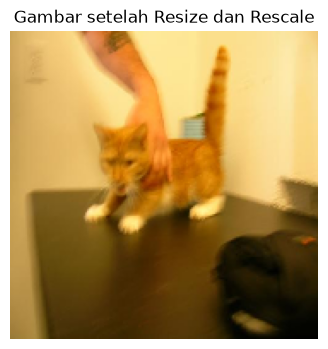

In [18]:
sample_path = next(
    f for f in (DATASET_DIR / "Cat").iterdir()
    if f.is_file() and f not in map(Path, invalid_files)
)

sample_image = tf.keras.utils.load_img(
    sample_path,
    target_size=(IMG_SIZE, IMG_SIZE)
)

sample_array = tf.keras.utils.img_to_array(sample_image)
sample_scaled = resize_and_rescale(
    tf.expand_dims(sample_array, axis=0)
)

print("Shape gambar:", sample_scaled.shape)
print("Nilai minimum:", float(tf.reduce_min(sample_scaled)))
print("Nilai maksimum:", float(tf.reduce_max(sample_scaled)))

plt.figure(figsize=(4, 4))
plt.imshow(sample_scaled[0].numpy())
plt.title("Gambar setelah Resize dan Rescale")
plt.axis("off")
plt.show()

## 3. Membuat dataset training dan validation

In [19]:
# Membaca gambar dari folder dan membuat dataset TensorFlow.
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(DATASET_DIR),
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(DATASET_DIR),
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

print("Urutan label:", train_ds.class_names)

Found 24998 files belonging to 2 classes.
Using 19999 files for training.
Found 24998 files belonging to 2 classes.
Using 4999 files for validation.
Urutan label: ['Cat', 'Dog']


In [20]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

## 4. Membuat Model CNN

In [21]:
model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    # Preprocessing 
    resize_and_rescale,
    data_augmentation,

    # Convolution block 1
    layers.Conv2D(
        32, kernel_size=3,
        padding="same", activation="relu"
    ),
    layers.MaxPooling2D(pool_size=2),

    # Convolution block 2
    layers.Conv2D(
        64, kernel_size=3,
        padding="same", activation="relu"
    ),
    layers.MaxPooling2D(pool_size=2),

    # Convolution block 3
    layers.Conv2D(
        128, kernel_size=3,
        padding="same", activation="relu"
    ),
    layers.MaxPooling2D(pool_size=2),

    # Mengubah feature map menjadi vektor
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output biner
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resize_and_rescale (Sequential) │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     7,929,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,023,361 (30.61 MB)

 Trainable params: 8,023,361 (30.61 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [23]:
from pathlib import Path
from PIL import Image

DATASET_DIR = Path("PetImages")

invalid_files = []

for class_name in ["Cat", "Dog"]:
    folder = DATASET_DIR / class_name

    for file_path in folder.iterdir():
        if not file_path.is_file():
            continue

        try:
            with Image.open(file_path) as img:
                img.load()

                if img.mode not in ["RGB", "RGBA", "L"]:
                    print(
                        "Format warna tidak biasa:",
                        file_path,
                        img.mode
                    )

        except Exception as e:
            invalid_files.append(file_path)
            print("Gambar bermasalah:", file_path, "|", e)

print("\nTotal file yang gagal dibaca:", len(invalid_files))

Format warna tidak biasa: PetImages\Cat\10125.jpg P
Format warna tidak biasa: PetImages\Cat\10501.jpg P
Format warna tidak biasa: PetImages\Cat\10820.jpg P
Format warna tidak biasa: PetImages\Cat\11095.jpg P
Format warna tidak biasa: PetImages\Cat\11210.jpg P
Format warna tidak biasa: PetImages\Cat\11565.jpg P
Format warna tidak biasa: PetImages\Cat\11874.jpg P
Format warna tidak biasa: PetImages\Cat\11935.jpg P
Format warna tidak biasa: PetImages\Cat\12080.jpg P
Format warna tidak biasa: PetImages\Cat\140.jpg P
Format warna tidak biasa: PetImages\Cat\2663.jpg P
Format warna tidak biasa: PetImages\Cat\3300.jpg P
Format warna tidak biasa: PetImages\Cat\3491.jpg P
Format warna tidak biasa: PetImages\Cat\4833.jpg P
Format warna tidak biasa: PetImages\Cat\5370.jpg P
Format warna tidak biasa: PetImages\Cat\5553.jpg P
Format warna tidak biasa: PetImages\Cat\6435.jpg P
Format warna tidak biasa: PetImages\Cat\660.jpg P
Format warna tidak biasa: PetImages\Cat\7968.jpg P
Format warna tidak biasa

In [24]:
from pathlib import Path
from PIL import Image
import shutil

SOURCE_DIR = Path("PetImages")
CLEAN_DIR = Path("PetImages_Clean")

for class_name in ["Cat", "Dog"]:
    source_folder = SOURCE_DIR / class_name
    target_folder = CLEAN_DIR / class_name

    target_folder.mkdir(parents=True, exist_ok=True)

    valid_count = 0
    skipped_count = 0

    for file_path in source_folder.iterdir():
        if not file_path.is_file():
            continue

        try:
            with Image.open(file_path) as img:
                img.load()
                rgb_img = img.convert("RGB")

                # Simpan dengan nama baru yang konsisten
                output_path = target_folder / f"{file_path.stem}.jpg"
                rgb_img.save(output_path, format="JPEG")

                valid_count += 1

        except Exception:
            skipped_count += 1

    print(f"{class_name}:")
    print("  Gambar valid:", valid_count)
    print("  Gambar dilewati:", skipped_count)

Cat:
  Gambar valid: 12499
  Gambar dilewati: 0
Dog:
  Gambar valid: 12499
  Gambar dilewati: 0


In [25]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    str(CLEAN_DIR),
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(150, 150),
    batch_size=32,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(CLEAN_DIR),
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(160, 160),
    batch_size=32,
    label_mode="binary"
)

# Simpan nama kelas sebelum mengubah dataset
class_names = train_ds.class_names

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Kelas:", class_names)

Found 24998 files belonging to 2 classes.
Using 19999 files for training.
Found 24998 files belonging to 2 classes.
Using 4999 files for validation.
Kelas: ['Cat', 'Dog']


In [26]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [27]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[early_stopping]
)

Epoch 1/25


c:\Users\saire\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


625/625 ━━━━━━━━━━━━━━━━━━━━ 219s 341ms/step - accuracy: 0.6280 - loss: 0.6403 - val_accuracy: 0.7153 - val_loss: 0.5614
Epoch 2/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 225s 354ms/step - accuracy: 0.7152 - loss: 0.5565 - val_accuracy: 0.7614 - val_loss: 0.4899
Epoch 3/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 222s 347ms/step - accuracy: 0.7607 - loss: 0.4962 - val_accuracy: 0.7890 - val_loss: 0.4517
Epoch 4/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 216s 339ms/step - accuracy: 0.7903 - loss: 0.4576 - val_accuracy: 0.8156 - val_loss: 0.4164
Epoch 5/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 213s 335ms/step - accuracy: 0.8048 - loss: 0.4319 - val_accuracy: 0.8228 - val_loss: 0.3993
Epoch 6/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 224s 353ms/step - accuracy: 0.8181 - loss: 0.4098 - val_accuracy: 0.8340 - val_loss: 0.3772
Epoch 7/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 225s 353ms/step - accuracy: 0.8244 - loss: 0.3909 - val_accuracy: 0.8368 - val_loss: 0.3775
Epoch 8/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 233s 366ms/step - accuracy: 0.8366 - loss: 0.37

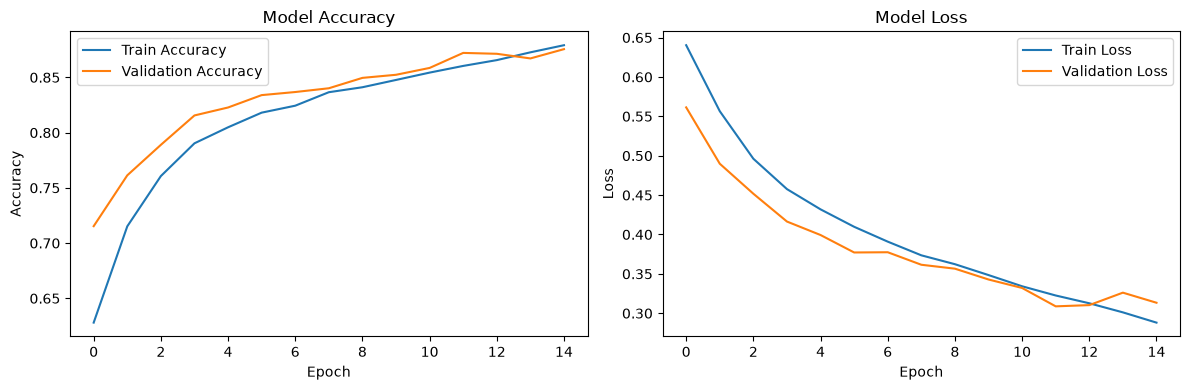

In [28]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

         Cat       0.50      0.49      0.50      2462
         Dog       0.52      0.53      0.52      2537

    accuracy                           0.51      4999
   macro avg       0.51      0.51      0.51      4999
weighted avg       0.51      0.51      0.51      4999



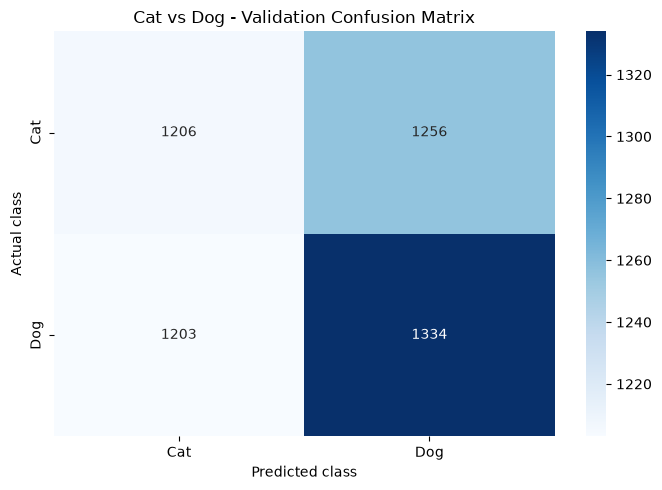

In [30]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# Jangan tulis ulang:
# class_names = train_ds.class_names
# Gunakan class_names yang sudah disimpan sebelumnya.

# Actual labels
y_true = np.concatenate([
    labels.numpy().ravel().astype(int)
    for _, labels in val_ds
])

# Predicted labels
y_pred = np.concatenate([
    (model.predict(images, verbose=0).ravel() >= 0.5).astype(int)
    for images, _ in val_ds
])

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Cat vs Dog - Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [31]:

# Save trained CNN model

model.save("cnn_dog_cat.keras")

print("Model successfully saved!")


Model successfully saved!
